#
**<h1 align="center">$\textbf{LAB Report: ODE}$</h1>**

<h4 align="right">$Name: Ahtasham Haider$</4>
<h4 align="right">$SC Code: SC26M004$</4>

---



# **Leapfrog Method**

The leapfrog method is a numerical method used to solve differential equations, especially when you want to simulate how something changes over time.

#### **The mathematical idea:** Consider a system whose motion is described by Newton's second law

<h2 align="center">$\frac{d^2x}{dt^2} = a(x)$</h2>

Here, $a(x)$ is the acceleration, which may depend on position.

This is a second-order differential equation, we can rewrite it as two first-order equations:

<h2 align="center">$\frac{dx}{dt} = v$</h2>

<h2 align="center">$\frac{dv}{dt} = a(x)$</h2>


The leapfrog method approximates both changes using a small time step $\Delta t$.

The two update rules

Step 1: Update velocity by half a time step.

<h3 align="center">$v_{n+1/2} = v_{n-1/2} + \Delta t \cdot a(x_n)$</h3>


Step 2: Update position by a full time step.

<h3 align="center">$x_{n+1} = x_n + \Delta t \cdot v_{n + 1/2}$</h3>

Then repeat the process using the new position.

Notice the staggered timing:

*   Velocity jumps from $t - Δt/2$ to $t + Δt/2$
*   Position jumps from $t$ to $t + Δt$




> [**REF**](https://chatgpt.com/s/t_6ad3a6e9e2308191ae737c6c9091816f)




## **Problem Statement:**

*   **Electron plasma oscillation**: An electron displaced from equilibrium in a uniform, fixed ion background feels an electric field
proportional to its displacement, and oscillates at the plasma frequency $ω_p$. In normalized units
($ω_p = 1$), the motion is

<h2 align="center">$\frac{dx}{dt} = v, \quad \frac{dv}{dt} = -\omega_p^2x, \quad \omega_p=1$</h2>

<h3 align="center">$x(0) = 0.5, \quad v(0) = 0, \quad 0 ≤t≤20$</h3>


*   **Exact solution:**:

<h3 align="center">$x(t) = 0.5cost,\quad v(t) = - 0.5sint$</h3>


## **Required packages**

In [308]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

In [309]:
# Initialize
x_0 = 0.5
v_0 = 0

t = (0, 20)

h = 0.1

# Compute the staggered starting velocity from:---->        v_{-1/2} = v_0 - h/2*a(x_0)
v_i = v_0 + h/2*x_0

t_step = np.arange(t[0], t[1] + h/2, h)
n = len(t_step)

x, v = np.zeros_like(t_step), np.zeros_like(t_step)
x_act, v_act = 0.5*np.cos(t_step), -0.5*np.sin(t_step - h/2)    # for velocity the t_step is calculated at h/2 behind
x[0], v[0] = x_0, v_i

In [310]:
def leapfrog(x, v, h):
    v = v - h*x
    x = x + h*v
    return x, v

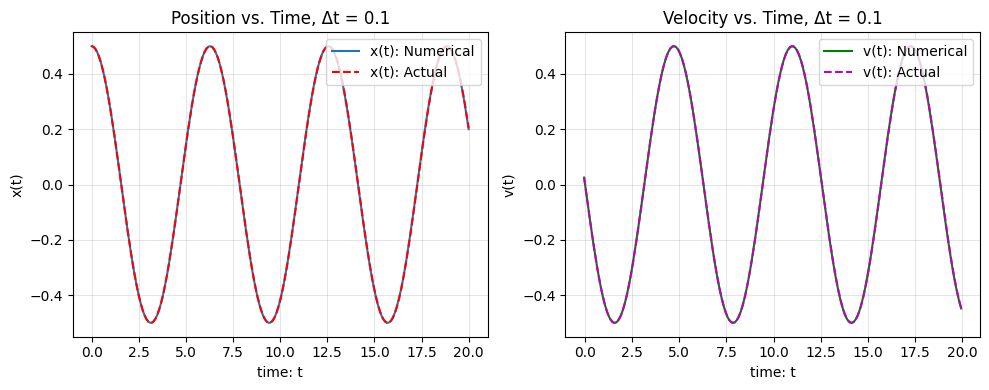

In [311]:
for i in range(1, n):
    x[i], v[i] = leapfrog(x[i-1], v[i-1], h)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(t_step, x, label='x(t): Numerical')
ax[0].plot(t_step, x_act, "r--", label='x(t): Actual')
ax[1].plot(t_step - h/2, v, "g", label='v(t): Numerical')
ax[1].plot(t_step - h/2, v_act, "m--", label='v(t): Actual')
ax[0].grid(True, color='black', alpha = 0.1 )
ax[1].grid(True, color='black', alpha = 0.1 )
ax[0].legend(loc='upper right')
ax[1].legend(loc='upper right')
ax[0].set_xlabel('time: t')
ax[0].set_ylabel('x(t)')
ax[1].set_xlabel('time: t')
ax[1].set_ylabel('v(t)')
ax[0].set_title(f'Position vs. Time, Δt = {h}')
ax[1].set_title(f'Velocity vs. Time, Δt = {h}')
plt.tight_layout()
plt.show()

In [312]:
# max Error:
max_err = np.max(np.abs(x_act - x))
print(f"Max Error: {max_err}")

# RMS Error:
rms_err = np.sqrt(np.mean((x_act-x)**2))
print(f"RMS Error: {rms_err}")

Max Error: 0.0038152808690173623
RMS Error: 0.0016642941801469462


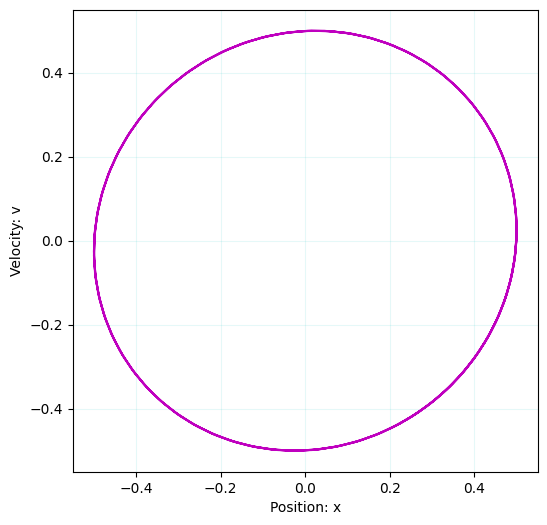

In [313]:
plt.figure(figsize=(6, 6))
plt.plot(x, v, "m")
plt.xlabel('Position: x')
plt.ylabel('Velocity: v')
plt.grid(True, color='c', alpha = 0.1)
plt.show()

## **Convergence Analysis**


*   To analyze the stability of a numerical method, we must mathematically track how an initial error grows or decays over successive execution steps.




In [314]:
h = np.linspace(0.2, 0.01, 20)      # Generating different Δt values
max_err = np.zeros_like(h)          # intializing err matrix
rms_err = np.zeros_like(h)

for i in range(len(h)):
    v_i = v_0 + h[i]/2*x_0          # computing stagered velocity

    t_step = np.arange(t[0], t[1] + h[i]/2, h[i])
    n = len(t_step)

    x_act = 0.5*np.cos(t_step)          # Actual Solution matrix
    v_act = -0.5*np.sin(t_step - h[i]/2)

    x, v = np.zeros_like(t_step), np.zeros_like(t_step)
    x[0], v[0] = x_0, v_i

    for j in range(1, n):
        x[j], v[j] = leapfrog(x[j-1], v[j-1], h[i])

    max_err[i] = np.max(np.abs(x_act - x))          # Computing Error
    rms_err[i] = np.sqrt(np.mean((x_act - x)**2))

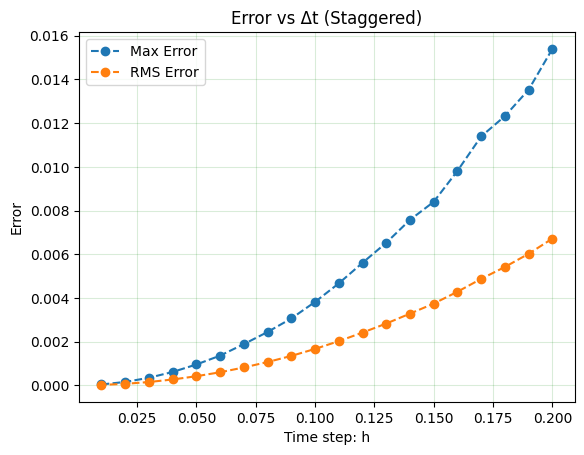

In [315]:
# Plotting Error vs Δt for Staggered Case:

plt.plot(h, max_err, "o--", label="Max Error")
plt.plot(h, rms_err, "o--", label="RMS Error")

plt.xlabel('Time step: h')
plt.ylabel('Error')
plt.grid(True, color='g', alpha=0.15)
plt.title("Error vs Δt (Staggered)")
plt.legend()
plt.show()

In [316]:
h = np.linspace(0.2, 0.01, 20)      # Generating different Δt values
max_err = np.zeros_like(h)          # intializing err matrix
rms_err = np.zeros_like(h)

for i in range(len(h)):
    v_i = v_0

    t_step = np.arange(t[0], t[1] + h[i]/2, h[i])
    n = len(t_step)

    x_act = 0.5*np.cos(t_step)          # Actual Solution matrix
    v_act = -0.5*np.sin(t_step - h[i]/2)

    x, v = np.zeros_like(t_step), np.zeros_like(t_step)
    x[0], v[0] = x_0, v_i

    for j in range(1, n):
        x[j], v[j] = leapfrog(x[j-1], v[j-1], h[i])

    max_err[i] = np.max(np.abs(x_act - x))          # Computing Error
    rms_err[i] = np.sqrt(np.mean((x_act - x)**2))

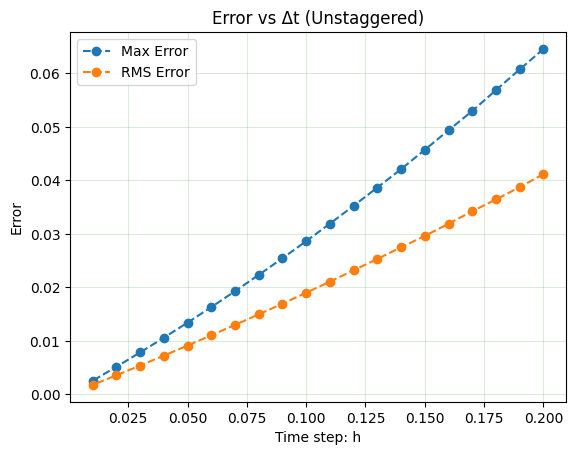

In [317]:
# Plotting Error vs Δt for Unstaggered Case:

plt.plot(h, max_err, "o--", label="Max Error")
plt.plot(h, rms_err, "o--", label="RMS Error")
plt.xlabel('Time step: h')
plt.ylabel('Error')
plt.grid(True, color='g', alpha=0.15)
plt.title("Error vs Δt (Unstaggered)")
plt.legend()
plt.show()

## **Derivation to Find the Order of the Method**

We start with the two core coupled update equations of the Leapfrog scheme:

$$v_{n+1/2} = v_{n-1/2} + h \cdot a(x_n) \quad \text{--- (1)}$$

$$x_{n+1} = x_n + h \cdot v_{n + 1/2} \quad \text{--- (2)}$$

#### Step 1: Express velocities in terms of positions
Rearranging equation (2) allows us to isolate the forward half-step velocity:

$$v_{n + 1/2} = \frac{x_{n+1} - x_{n}}{h} \quad \text{--- (3)}$$

By shifting the index of equation (3) backward by one time step ($n \rightarrow n-1$), we find the expression for the backward half-step velocity:

$$v_{n - 1/2} = \frac{x_{n} - x_{n-1}}{h} \quad \text{--- (4)}$$

#### Step 2: Substitute and simplify
Substituting equations (3) and (4) into equation (1), and substituting the electron plasma acceleration $a(x_n) = -\omega_p^2 x_n$, we get:

$$\frac{x_{n+1} - x_{n}}{h} = \frac{x_{n} - x_{n-1}}{h} - h\omega_p^2 x_n$$

Multiplying the entire equation by $h$ to clear the denominators:

$$x_{n+1} - x_{n} = x_{n} - x_{n-1} - \omega_p^2 h^2 x_n$$

#### Step 3: Rearrange terms
Gathering all position variables onto the left-hand side yields the final **central-difference formula**:

$$\mathbf{x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n}$$


## **stability Analysis**

$$\mathbf{x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n} \quad \text{--- (1)}$$

Rearranging all terms to one side:
$$\mathbf{x_{n+1} - (2 -\omega_p^2 h^2)x_n + x_{n-1} = 0} \quad \text{--- (1)}$$

We assume a solution of the form $x_n = g^n$, where $g$ is the amplification factor (characteristic root). Substituting this gives:
$$\mathbf{g^{n+1} - (2 -\omega_p^2 h^2)g^n + g^{n-1} = 0} \quad \text{--- (1)}$$

Dividing the entire equation by $g^{n-1}$ yields
$$ g^2 - (2 -\omega_p^2 h^2)g + 1 = 0 \quad \text{--- (1)}$$

This is in the standard quadratic form $\mathbf{g^2 - Bg + 1 = 0}$, where $B = 2 - \omega_p^2 h^2$

For the numerical system to be stable (non-growing), the roots must not exceed a magnitude of 1 ($|g| \le 1$). This happens if and only if the discriminant of the quadratic equation is negative:
$$B^2 - 4 < 0 \implies |B| < 2$$

Substitute $B = 2 - \omega_p^2 h^2$ back into the inequality:
$$ -2 < 2 - \omega_p^2 h^2 < 2$$
$$ 0 <\omega_p^2 h^2 < 4$$

which gives the stability criteria::
$$ \omega_p h < 2$$

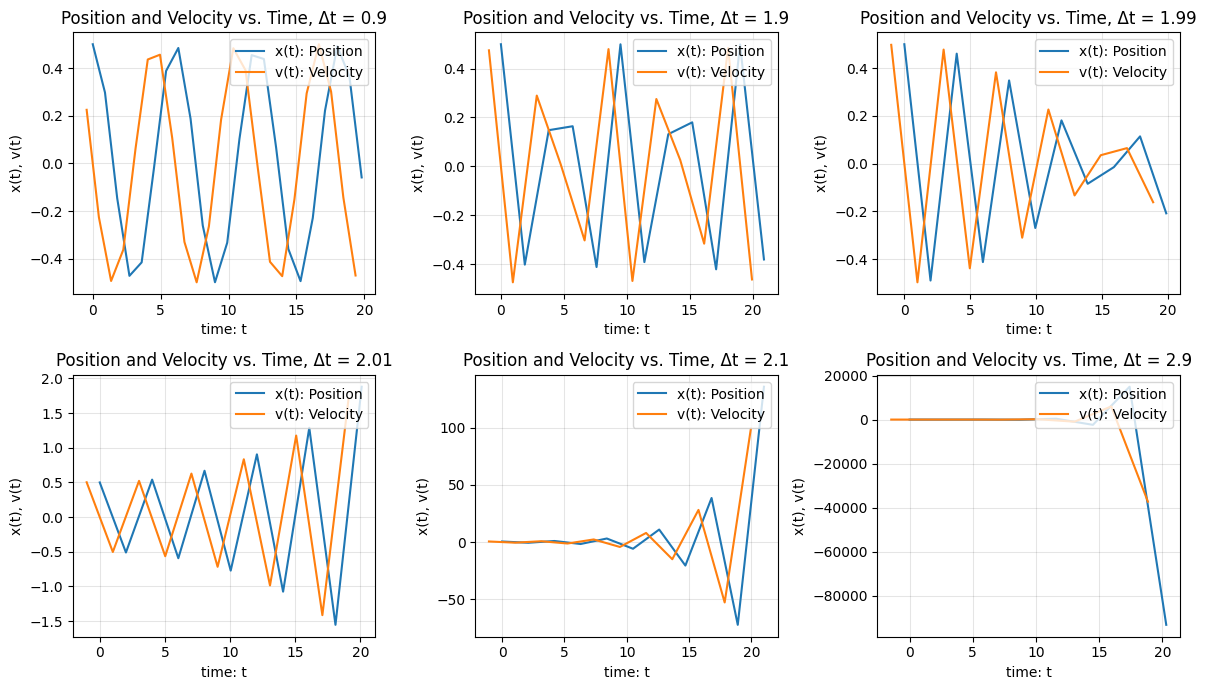

In [318]:
H = np.array([0.9, 1.9, 1.99, 2.01, 2.1, 2.9])

fig, ax = plt.subplots(2, 3, figsize=(12, 7))
ax = ax.flatten()

for i in range(len(H)):
    v_i = v_0 + H[i]/2*x_0

    t_step = np.arange(t[0], t[1] + H[i]/2, H[i])

    n = len(t_step)

    x, v = np.zeros_like(t_step), np.zeros_like(t_step)
    x[0], v[0] = x_0, v_i

    for j in range(1, n):
        x[j], v[j] = leapfrog(x[j-1], v[j-1], H[i])

    ax[i].plot(t_step, x, label='x(t): Position')
    ax[i].plot(t_step - H[i]/2, v, label='v(t): Velocity')
    ax[i].grid(True, color='black', alpha = 0.1)
    ax[i].legend(loc='upper right')
    ax[i].set_xlabel('time: t')
    ax[i].set_ylabel('x(t), v(t)')
    ax[i].set_title(f'Position and Velocity vs. Time, Δt = {H[i]}')

plt.tight_layout()
plt.show()

## **Results and Dicussion**

*   Numerical Solution well approinmated the actual solution for Δt=0.1 with Maximum Error = 0.0038 and RMS Error: 0.0017.
*   For Staggered case the Maximum Error and RMS Error decrease with the order of $Δt^2$. This is result is also shown by the derivation. For Unstaggered case both the error decrease with the order of $Δt$.
*   The Stability Analysis shows that the system is stable when $\omega_p h < 2$. Since $\omega_p = 1$ all the plots for $h\lt2$ are converging towards originial solution and for $h\gt2$ all the plots are diverging towards $∞$.


## **References**
https://en.wikipedia.org/wiki/Leapfrog_integration
